# 04 · Results

*Part 4 of 4 · Previous: [03 · Baselines and model](03_baselines_and_model.ipynb) · Back to the start: [01 · Data and context](01_data_and_context.ipynb)*

We open the test period (Jan – Jun 2026), untouched until now, and apply the model and the alert line exactly as
fixed in validation: the model still beats the three versions of the rule of five. Then we explain why it detects
fewer failures than in validation, what pushes its alerts (SHAP), and what the app shows.

In [1]:
from backblaze_hdd_failure_prediction.figures import use_style
from backblaze_hdd_failure_prediction.notebooks import results as nb

use_style()
con = nb.connect()
nb.show_working_threshold()

Working threshold: 0.8340


## 1 · Test, untouched until now

Nothing was chosen by looking at test: not the variables, the tuning or the threshold. We apply the same
`lightgbm_v1` with the working threshold and count per drive life, as in notebook 03.

> **Decision:** no retraining on training + validation before test. **Why:** the threshold needs a clean period to
> be fixed on, outside the model's training data. **Discarded:** retraining now; it comes in v3 with a scheme
> designed for it. The cost: two large drive models absent from training stay in "others".

> **Decision:** two sets of numbers. **Why:** the threshold fixed in validation, applied as it is, is the
> operational result. Thresholds matched on test (A and B) compare exactly with each rule, but they use the test
> labels, so they are not a prediction.

In [2]:
nb.show_test_results()

Test: 2,552 failures, 355,201 other lives


,detected,detected %,with margin,median lead (days),false alarms,false alarms per 100 healthy lives,"random, same false alarms"
LightGBM at 0.834,"1,778",69.7,"1,627",15,"6,483",1.83,
Static rule,"2,040",79.9,"1,916",15,"31,413",8.84,22
7-day rule,"1,658",65.0,"1,559",15,"14,589",4.11,8
30-day rule,"1,777",69.6,"1,630",15,"15,313",4.31,8


In [3]:
nb.show_matched_thresholds()

validation PR-AUC 0.1182, random 0.00044 (266 times)
test       PR-AUC 0.1045, random 0.00058 (179 times)


,A: rule detects,A: model detects,B: rule false alarms,B: model false alarms,B: % fewer,"threshold A, validation → test","threshold B, validation → test"
Static rule,"2,040","2,121","31,413","20,586",34,0.210 → 0.204,0.5015 → 0.3481
7-day rule,"1,658","1,992","14,589","4,262",71,0.512 → 0.511,0.9101 → 0.8965
30-day rule,"1,777","2,001","15,313","6,428",58,0.494 → 0.487,0.8340 → 0.8361


The operating curve shows every threshold at once. We compute it with `evaluation.model_at` over a grid of
thresholds, denser near the top.

In [4]:
nb.load_test(con)  # tables `period` (the rules, per life), `model_period` and `model_positive` (the model)
curve = nb.operating_curve(con)
nb.show_fixed_threshold(con)

53 thresholds. At 0.8340: 1,778 detected, 6,483 false alarms, as in lightgbm_v1.csv


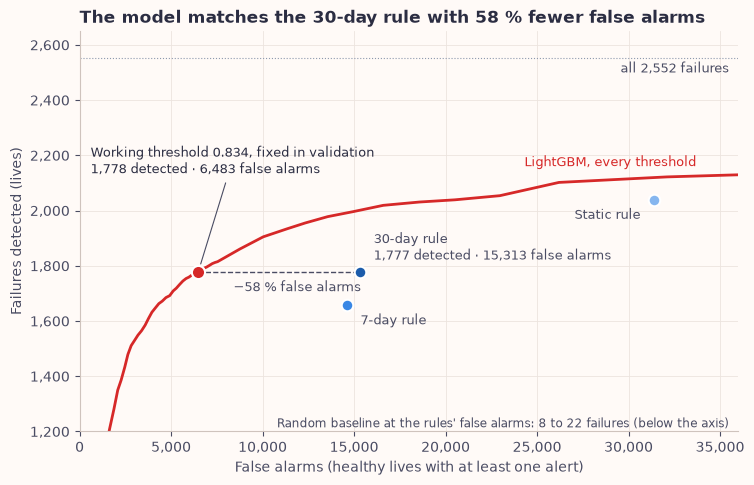

In [5]:
nb.plot_operating_curve_test(curve)

**What we see**

- At the threshold fixed in validation the model detects 1,778 of 2,552 failures (69.7 %), 1,627 with margin,
  median lead time 15 days, with 6,483 false alarms among 355,201 healthy lives. The 30-day rule detects 1,777
  with 15,313: the same failures, 58 % fewer false alarms.
- Matched on test, the model beats every rule. A: 2,121 vs 2,040, 1,992 vs 1,658, 2,001 vs 1,777 failures.
  B: 34 % to 71 % fewer false alarms.
- Against the 30-day rule the matched threshold is 0.8361 in test and 0.8340 in validation: the operating point
  is stable. (Against the static rule it moves, 0.50 → 0.35, because the curve is flat there.)
- PR-AUC over every labelled drive-day: 0.1045, 179 times the random value (0.00058); 0.1182 in validation.

## 2 · Validation and test side by side

The model detects 69.7 % of the failures in test against 72.5 % in validation. Before blaming it, we look at the
rules, which learned nothing from the data, and at the healthy drives.

validation                                          test  \
                  detected % false alarms per 100 healthy lives detected %   
LightGBM at 0.834      72.48                               1.85      69.67   
Static rule            79.36                               8.45      79.94   
7-day rule             66.27                               3.96      64.97   
30-day rule            72.48                               4.11      69.63   

                                                      
                  false alarms per 100 healthy lives  
LightGBM at 0.834                               1.83  
Static rule                                     8.84  
7-day rule                                      4.11  
30-day rule                                     4.31

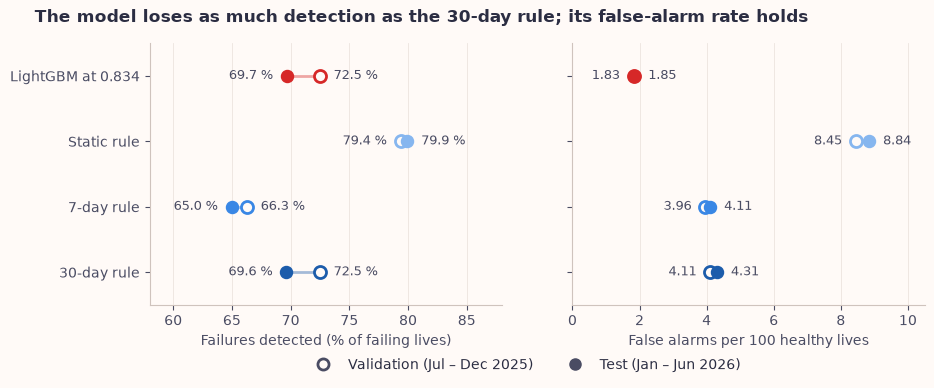

In [6]:
nb.show_validation_vs_test()

**What we see**

- The 30-day rule drops as much as the model (−2.9 points against −2.8); the 7-day rule a little, the static rule
  not at all.
- With the healthy drives nothing changes: 1.85 and 1.83 false alarms per 100 healthy lives.
- A stale model would get worse on both sides. Here a rule that learned nothing drops just as much: the failures
  changed, not the model. This is *data drift*: the data a model meets change over time.

## 3 · Why the model detects fewer failures in test

Each failure goes into a group by what the rule of five saw in its labelled days
(`evaluation.signal_before_failure`): **no signal** (none of the five above 0), **flat** (some above 0, none rising
over 30 days) or **rising**. `lightgbm_v1_failures.parquet` has one row per failure with its group, its drive model
and who detected it.

In [7]:
groups = nb.failures_by_signal(con)
nb.show_failures_by_signal(groups)

In [8]:
nb.show_mix_effect(groups)

Model: 72.5 % in validation, 69.7 % in test (2.8 points)
Validation rate of each group, test mix: 1,817 of 2,552 (71.2 %)
The mix explains 1.3 of the 2.8 points (46 %)


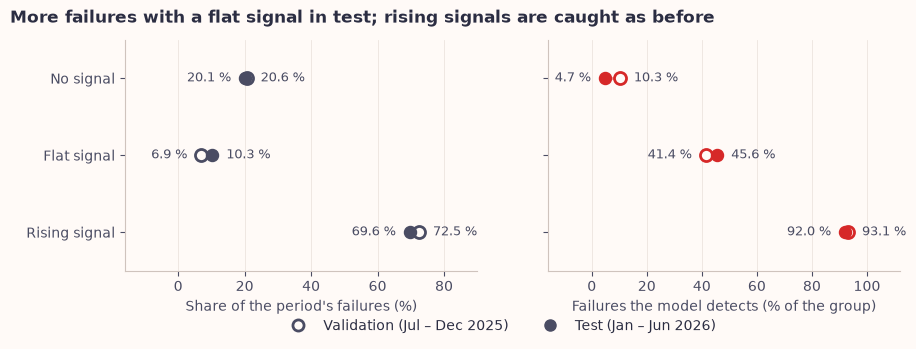

In [9]:
nb.plot_drop_by_signal(groups)

Which drive models bring more failures without signal in test?

In [10]:
nb.show_drive_models(con)

,"failures, validation","failures, test","no signal, validation","no signal, test","no signal, model detects (both)","model detects, validation","model detects, test"
drive_model,,,,,,,
ST24000NM002H,111,156,74,141,0,33,14
TOSHIBA MG08ACA16TEY,0,72,0,28,0,0,31
WDC WUH721816ALE6L4,110,144,18,42,3,67,63
TOSHIBA MG08ACA16TA,153,204,54,67,0,76,105
TOSHIBA MG10ACA20TE,49,106,20,33,0,28,64


Model detects, % of failures, with and without ST24000NM002H:


,all failures,without it
period,,
validation,72.5,75.1
test,69.7,73.6


**What we see**

- Failures without signal keep their share (20.6 % → 20.1 %); flat ones almost double (6.9 % → 10.3 %). The 30-day
  rule cannot see flat signals by construction and the static rule can, so only the first drops.
- The model detects 92–93 % of the rising signals in both periods. With validation's rate per group and test's mix
  it would detect 71.2 %: the mix explains 1.3 of the 2.8 points. Most of the rest is failures without signal,
  caught 41 of 399 times in validation and 24 of 512 in test.
- The Seagate ST24000NM002H (24 TB) stands out: 111 → 156 failures, those without signal 74 (2 in 3) → 141
  (9 in 10), and the model detects none of those. Without it the model goes from 75.1 % to 73.6 %: 1.5 points of
  drop instead of 2.8. (The MG08ACA16TEY has no failures in validation: the episode's count as retirements.)
- Backblaze's reports do not explain it, so its failures stay; its Q1 2026 report mentions mechanical problems
  (writes, reboots) in unnamed models. Real failures without warning: a limitation of the test period.

## 4 · What pushes the alerts

SHAP splits a drive-day's score among the variables, in the model's internal scale (log-odds); the parts add up to
the score. LightGBM computes it itself (`pred_contrib=True`, 0.09 s per row), so only the first alert of each life in
validation is explained. As in the app, a variable's **weight** in an alert is its SHAP value over the sum of the
absolute SHAP values of that alert. First, the top of the app's list on its default day:

In [11]:
alerts = nb.validation_alerts()  # the 7,683 first alerts of validation, with their SHAP values
nb.show_example_alert(alerts)

7,683 first alerts, 131 variables
ST12000NM0008, first alert on 31 Dec 2025, score 0.985; it failed 12 days later


,variable,value that day,weight %
0,187 Reported uncorrectable errors · value that...,27,22.0
1,187 Reported uncorrectable errors · 30-day change,+24,20.2
2,188 Command timeouts · 30-day change,"+51,542,491,180",19.5
3,187 Reported uncorrectable errors · 7-day change,+22,15.6
4,188 Command timeouts · 7-day change,"+51,542,491,180",6.2
5,Drive model,ST12000NM0008,2.6


Uncorrectable errors (187) and command timeouts (188) carry most of this alert's weight, and the drive failed
within 15 days. (Seagate's raw 188 jumps by billions, probably several counters in one number; not checked.)

Now all 7,683 alerts. Per attribute we add its value of the day and its 7- and 30-day changes (the normalized value
of 1 and 7 apart), split what raises and what lowers the score, and average. "Top push" is the share of alerts
whose strongest raising variable is in that group.

In [12]:
weights = nb.weights_by_group(alerts)
nb.show_weights(weights)

,rank,mean weight %,raises %,lowers %,"top push, % of alerts"
197 Current pending sectors,1,39.7,38.8,-0.9,70.3
5 Reallocated sectors,2,17.8,16.7,-1.1,14.4
187 Reported uncorrectable errors,3,11.0,9.6,-1.4,8.8
Drive model,4,3.9,2.7,-1.2,0.9
198 Offline uncorrectable sectors,5,3.9,3.7,-0.2,0.2
192 Power-off retract count,6,2.9,2.3,-0.6,3.3
9 Power-on hours,14,1.2,0.4,-0.8,0.0
Physical age,24,0.4,0.2,-0.2,0.0


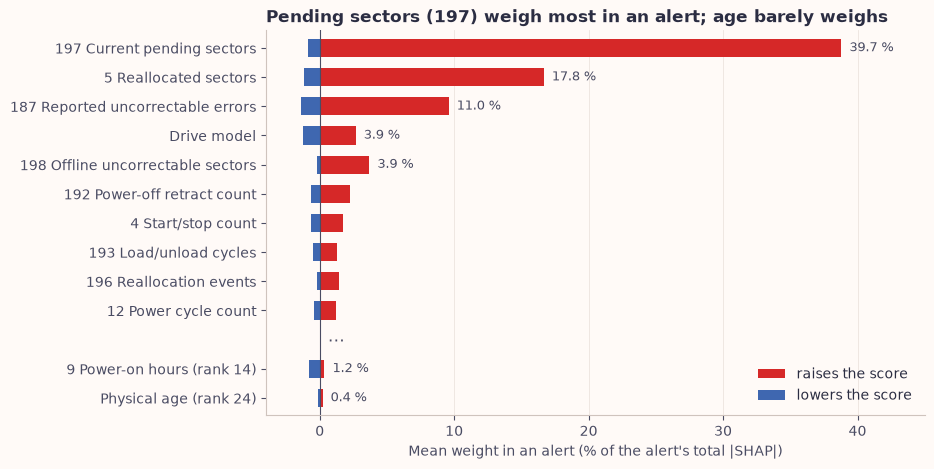

In [13]:
nb.plot_shap_weights(weights)

**What we see**

- 197 (current pending sectors) is the top push in 70.3 % of the alerts and carries 39.7 % of the weight on
  average; then come 5, 187, the drive model and 198.
- Four of the first five belong to the rule of five: the model watches the same counters, but uses how high they
  are and how fast they change, not just "above 0".
- Age barely weighs: attribute 9 (power-on hours) ranks 14th (1.2 %), physical age 24th (0.4 %). Next to direct
  signs of damage, age adds little.

## 5 · The app, limitations and next versions

The Streamlit app shows a validation day as if it were today: the lives that cross the alert line for the first
time, ordered by score. For a chosen drive it shows the variables that weigh most and its daily score against the
alert line. It runs locally, in English and Spanish:

```bash
uv run streamlit run src/backblaze_hdd_failure_prediction/app.py
```

**Limitations.** The label depends partly on the signal itself: in Backblaze's Q3 2024 report, 53 % of the failures
were proactive replacements, triggered partly by S.M.A.R.T. The MG08 episode is relabelled only because Backblaze
explained it. Location is in the gold layer but not used. No calibration: trained on every positive day and 0.5 %
of the negative ones, the score ranks drives well but is not their real probability of failing.

**Next.** v2: location, with an exploration and an ablation (the model with and without it). v3: XGBoost and
CatBoost with the same tuning budget and bootstrap intervals, plus logistic regression and drive model + age
baselines.

## Takeaways

- On unseen data, with the threshold fixed beforehand, the model detects as many failures as the best rule (1,778
  vs 1,777) with 58 % fewer false alarms.
- It detects fewer failures than in validation (69.7 % vs 72.5 %), but so does the 30-day rule, and its false
  alarms per healthy life do not change: the failures changed, not the model.
- More flat-signal failures explain about half of the drop; most of the rest is failures with no warning, many of
  them from one 24 TB drive model.
- The alerts are driven by the damage counters of the rule of five, above all 197; age barely weighs.

This closes v1. Next: location (v2) and a fair comparison with XGBoost and CatBoost (v3).